# Phân cụm phân cấp

*Bài 8, mục 8.1.4.* Phân cụm gộp (agglomerative, bottom-up): ban đầu mỗi điểm là một cụm; mỗi bước gộp hai cụm gần nhau nhất; lặp tới khi chỉ còn một cụm. Quá trình gộp được biểu diễn bằng cây **dendrogram**. Khoảng cách giữa hai cụm được định nghĩa bởi **tiêu chí liên kết** (linkage).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

X = np.array([[1, 1], [1.5, 1.5], [5, 5], [3, 4], [4, 4], [3, 3.5]])
names = ['A', 'B', 'C', 'D', 'E', 'F']
D = squareform(pdist(X))                     # ma trận khoảng cách Euclid giữa các điểm
print('Ma trận khoảng cách:')
print('     ' + '      '.join(names))
for name, row in zip(names, D):
    print(name, ' '.join('%6.2f' % d for d in row))

Ma trận khoảng cách:
     A      B      C      D      E      F
A   0.00   0.71   5.66   3.61   4.24   3.20
B   0.71   0.00   4.95   2.92   3.54   2.50
C   5.66   4.95   0.00   2.24   1.41   2.50
D   3.61   2.92   2.24   0.00   1.00   0.50
E   4.24   3.54   1.41   1.00   0.00   1.12
F   3.20   2.50   2.50   0.50   1.12   0.00


## 1. Cài đặt thuật toán gộp từng bước

In [2]:
def cluster_distance(c1, c2, linkage):
    """Khoảng cách giữa hai cụm (danh sách chỉ số điểm) theo tiêu chí liên kết."""
    pair = D[np.ix_(c1, c2)]                 # khoảng cách mọi cặp điểm giữa hai cụm
    if linkage == 'single':
        return pair.min()
    if linkage == 'complete':
        return pair.max()
    if linkage == 'average':
        return pair.mean()
    if linkage == 'centroid':
        return np.linalg.norm(X[c1].mean(axis=0) - X[c2].mean(axis=0))


def agglomerative(linkage):
    clusters = [[i] for i in range(len(X))]  # ban đầu mỗi điểm là một cụm
    step = 1
    while len(clusters) > 1:
        best = None
        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                d = cluster_distance(clusters[i], clusters[j], linkage)
                if best is None or d < best[0]:
                    best = (d, i, j)
        d, i, j = best
        label = lambda c: ''.join(names[k] for k in sorted(c))
        print('Bước %d: gộp %-5s và %-5s ở khoảng cách %.3f' % (step, label(clusters[i]), label(clusters[j]), d))
        clusters[i] = clusters[i] + clusters[j]
        del clusters[j]
        step += 1


for linkage in ['single', 'complete']:
    print('===== %s linkage =====' % linkage)
    agglomerative(linkage)

===== single linkage =====
Bước 1: gộp D     và F     ở khoảng cách 0.500
Bước 2: gộp A     và B     ở khoảng cách 0.707
Bước 3: gộp DF    và E     ở khoảng cách 1.000
Bước 4: gộp C     và DEF   ở khoảng cách 1.414
Bước 5: gộp AB    và CDEF  ở khoảng cách 2.500
===== complete linkage =====
Bước 1: gộp D     và F     ở khoảng cách 0.500
Bước 2: gộp A     và B     ở khoảng cách 0.707
Bước 3: gộp DF    và E     ở khoảng cách 1.118
Bước 4: gộp C     và DEF   ở khoảng cách 2.500
Bước 5: gộp AB    và CDEF  ở khoảng cách 5.657


## 2. Kiểm tra với SciPy và vẽ dendrogram

`linkage` trả về ma trận $(N-1) \times 4$: mỗi hàng là một lần gộp (chỉ số hai cụm, khoảng cách, số điểm của cụm mới). Cụm mới tạo ở bước $t$ có chỉ số $N + t - 1$.

[[3.    5.    0.5   2.   ]
 [0.    1.    0.707 2.   ]
 [4.    6.    1.    3.   ]
 [2.    8.    1.414 4.   ]
 [7.    9.    2.5   6.   ]]


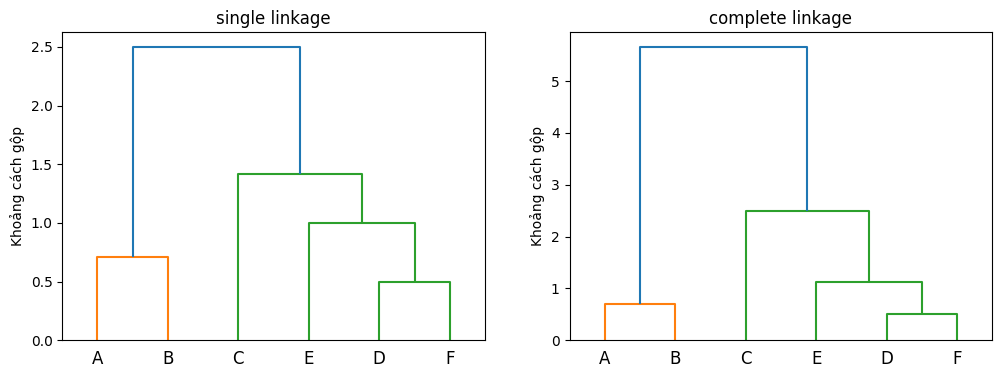

In [3]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

Z = linkage(X, method='single')
print(Z.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, method in zip(axes, ['single', 'complete']):
    dendrogram(linkage(X, method=method), labels=names, ax=ax)
    ax.set_title('%s linkage' % method); ax.set_ylabel('Khoảng cách gộp')
plt.show()

## 3. Cắt dendrogram để lấy cụm

Cắt cây bằng một đường ngang ở độ cao $h$: các nhánh bị cắt là các cụm. `fcluster` cắt theo độ cao (`criterion='distance'`) hoặc theo số cụm mong muốn (`criterion='maxclust'`).

In [4]:
Z = linkage(X, method='complete')
print('Cắt ở độ cao 2.5   :', fcluster(Z, t=2.5, criterion='distance'))
print('Lấy đúng 2 cụm     :', fcluster(Z, t=2, criterion='maxclust'))
print('Lấy đúng 3 cụm     :', fcluster(Z, t=3, criterion='maxclust'))

Cắt ở độ cao 2.5   : [1 1 2 2 2 2]
Lấy đúng 2 cụm     : [1 1 2 2 2 2]
Lấy đúng 3 cụm     : [1 1 3 2 2 2]


## 4. So sánh các tiêu chí liên kết trên dữ liệu có hình dạng khác nhau

Single linkage nối được các cụm có hình dạng kéo dài nhưng dễ bị "hiệu ứng chuỗi"; complete, average, Ward ưu tiên các cụm tròn, gọn. Ward (mặc định của scikit-learn) gộp hai cụm làm tổng bình phương sai số trong cụm tăng ít nhất, tương tự mục tiêu của K-means.

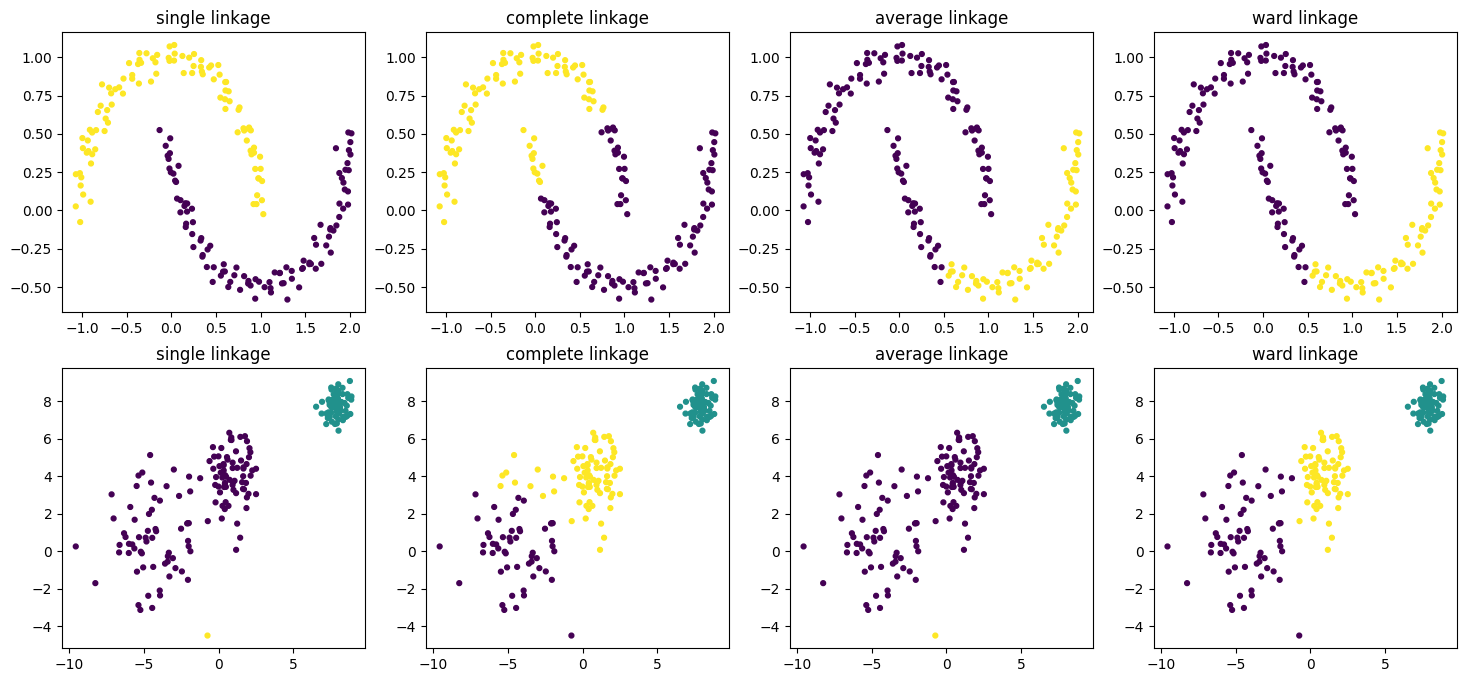

In [5]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import make_blobs, make_moons

X_moons, _ = make_moons(n_samples=200, noise=0.05, random_state=0)
X_blobs, _ = make_blobs(n_samples=200, centers=3, cluster_std=[1.0, 2.0, 0.5], random_state=3)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for row, data in enumerate([X_moons, X_blobs]):
    for col, method in enumerate(['single', 'complete', 'average', 'ward']):
        k = 2 if row == 0 else 3
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(data)
        axes[row, col].scatter(data[:, 0], data[:, 1], c=labels, cmap='viridis', s=12)
        axes[row, col].set_title('%s linkage' % method)
plt.show()

## 5. Thực hành theo giáo trình: Agglomerative Clustering và dendrogram

30 điểm từ 3 cụm (`make_blobs`). Để vẽ dendrogram từ mô hình scikit-learn, huấn luyện với `distance_threshold=0, n_clusters=None` (dựng toàn bộ cây) rồi tạo ma trận liên kết từ `children_`, `distances_`.

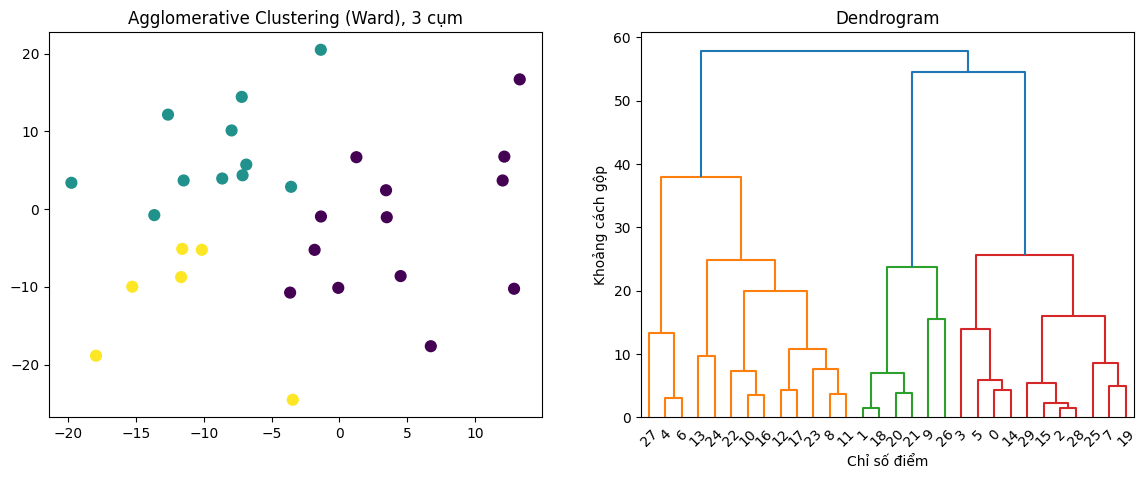

In [6]:
X30, _ = make_blobs(n_samples=30, centers=3, cluster_std=10, random_state=42)
labels = AgglomerativeClustering(n_clusters=3).fit_predict(X30)
model = AgglomerativeClustering(distance_threshold=0, n_clusters=None).fit(X30)


def plot_dendrogram(model, **kwargs):
    counts = np.zeros(model.children_.shape[0])      # số điểm trong mỗi cụm được gộp
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        counts[i] = sum(1 if child < n_samples else counts[child - n_samples] for child in merge)
    linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)
    dendrogram(linkage_matrix, **kwargs)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(X30[:, 0], X30[:, 1], c=labels, cmap='viridis', s=60)
ax1.set_title('Agglomerative Clustering (Ward), 3 cụm')
plt.sca(ax2)
plot_dendrogram(model)
ax2.set_title('Dendrogram'); ax2.set_xlabel('Chỉ số điểm'); ax2.set_ylabel('Khoảng cách gộp')
plt.show()